In [2]:
%pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Note: you may need to restart the kernel to use updated packages.


In [3]:

from pathlib import Path
import sys
import sqlite3

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# The notebook should be running inside RiskLens/notebooks.
CURRENT = Path.cwd()

if CURRENT.name == "notebooks":
    ROOT = CURRENT.parent
elif CURRENT.name == "RiskLens":
    ROOT = CURRENT
else:
    raise ValueError(
        f"Current folder: {CURRENT}\n"
        "open this notebook from RiskLens/notebooks."
    )

for folder in [
    "data_raw",
    "data_processed",
    "notebooks",
    "database",
    "outputs",
    "reports",
    "evidence",
    "powerbi"
]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

print("Python version:", sys.version.split()[0])
print("Project folder:", ROOT)
print("Dataset folder:", ROOT / "data_raw")

Python version: 3.11.13
Project folder: C:\Users\tiwar\Documents\RiskLens
Dataset folder: C:\Users\tiwar\Documents\RiskLens\data_raw


In [4]:
DATA_FILE = ROOT / "data_raw" / "bs140513_032310.csv"

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Dataset not found at:\n{DATA_FILE}\n"
        "Move the extracted BankSim transaction CSV into data_raw."
    )

raw = pd.read_csv(DATA_FILE)

print("Rows and columns:", raw.shape)
print("\nColumn names:")
print(raw.columns.tolist())

display(raw.head())

Rows and columns: (594643, 10)

Column names:
['step', 'customer', 'age', 'gender', 'zipcodeOri', 'merchant', 'zipMerchant', 'category', 'amount', 'fraud']


,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,'C1093826151','4','M','28007','M348934600','28007','es_transportation',4.55,0
1,0,'C352968107','2','M','28007','M348934600','28007','es_transportation',39.68,0
2,0,'C2054744914','4','F','28007','M1823072687','28007','es_transportation',26.89,0
3,0,'C1760612790','3','M','28007','M348934600','28007','es_transportation',17.25,0
4,0,'C757503768','5','M','28007','M348934600','28007','es_transportation',35.72,0


In [5]:
required = {"step", "category", "amount", "fraud"}

assert required.issubset(raw.columns), "Required columns are missing."

quality = pd.DataFrame({
    "data_type": raw.dtypes.astype(str),
    "missing_values": raw.isna().sum(),
    "unique_values": raw.nunique(dropna=False)
})

display(quality)

print("Exact duplicate rows:", raw.duplicated().sum())
print("\nFraud label counts:")
print(raw["fraud"].value_counts(dropna=False))

assert raw["fraud"].notna().all(), "Missing fraud labels found."
assert set(raw["fraud"].unique()).issubset({0, 1}), (
    "Unexpected fraud labels found."
)

summary = pd.DataFrame([{
    "transactions": len(raw),
    "fraud_transactions": int(raw["fraud"].sum()),
    "fraud_rate_percent": raw["fraud"].mean() * 100,
    "missing_cells": int(raw.isna().sum().sum()),
    "exact_duplicate_rows": int(raw.duplicated().sum()),
    "first_step": raw["step"].min(),
    "last_step": raw["step"].max()
}])

display(summary)

quality.to_csv(ROOT / "outputs" / "data_quality.csv")
summary.to_csv(
    ROOT / "outputs" / "dataset_summary.csv",
    index=False
)

print("Data-quality outputs saved.")

,data_type,missing_values,unique_values
step,int64,0,180
customer,object,0,4112
age,object,0,8
gender,object,0,4
zipcodeOri,object,0,1
merchant,object,0,50
zipMerchant,object,0,1
category,object,0,15
amount,float64,0,23767
fraud,int64,0,2


Exact duplicate rows: 0

Fraud label counts:
fraud
0    587443
1      7200
Name: count, dtype: int64


,transactions,fraud_transactions,fraud_rate_percent,missing_cells,exact_duplicate_rows,first_step,last_step
0,594643,7200,1.210811,0,0,0,179


Data-quality outputs saved.


In [6]:
df = raw.copy()

# Cleaning the text without replacing missing values with literal strings.
text_columns = df.select_dtypes(
    include=["object", "string"]
).columns

for col in text_columns:
    df[col] = (
        df[col].astype("string")
        .str.strip()
        .str.strip("'\"")
        .str.strip()
    )

# Checking numeric fields.
for col in ["step", "amount", "fraud"]:
    df[col] = pd.to_numeric(df[col], errors="raise")

assert df[["step", "amount", "fraud"]].notna().all().all()
assert np.isfinite(df[["step", "amount", "fraud"]]).all().all()
assert (df["amount"] >= 0).all(), "Negative amounts need investigation."
assert (df["step"] >= 0).all()
assert (df["step"] % 1 == 0).all()
assert df["fraud"].isin([0, 1]).all()

df["step"] = df["step"].astype(int)
df["fraud"] = df["fraud"].astype(int)

print("Blank text values:")
print(df[text_columns].eq("").sum())

print("\nAge codes:", sorted(df["age"].dropna().unique()))
print("Gender codes:", sorted(df["gender"].dropna().unique()))

constant_columns = [
    col for col in df.columns
    if df[col].nunique(dropna=False) == 1
]

print("\nConstant columns:", constant_columns)
print("Duplicate rows after text cleaning:", df.duplicated().sum())

# Stable link to each original CSV row; never a model predictor.
df.insert(0, "transaction_id", np.arange(1, len(df) + 1))

display(df.head())

df.to_csv(
    ROOT / "data_processed" / "banksim_cleaned.csv",
    index=False
)

print("Cleaned dataset saved.")

Blank text values:
customer       0
age            0
gender         0
zipcodeOri     0
merchant       0
zipMerchant    0
category       0
dtype: Int64

Age codes: ['0', '1', '2', '3', '4', '5', '6', 'U']
Gender codes: ['E', 'F', 'M', 'U']

Constant columns: ['zipcodeOri', 'zipMerchant']
Duplicate rows after text cleaning: 0


,transaction_id,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,1,0,C1093826151,4,M,28007,M348934600,28007,es_transportation,4.55,0
1,2,0,C352968107,2,M,28007,M348934600,28007,es_transportation,39.68,0
2,3,0,C2054744914,4,F,28007,M1823072687,28007,es_transportation,26.89,0
3,4,0,C1760612790,3,M,28007,M348934600,28007,es_transportation,17.25,0
4,5,0,C757503768,5,M,28007,M348934600,28007,es_transportation,35.72,0


Cleaned dataset saved.


In [7]:
assert set(df["step"].unique()) == set(range(180))

df["split"] = np.select(
    [df["step"] < 108, df["step"] < 144],
    ["train", "validation"],
    default="test"
)

split_summary = (
    df.groupby("split")
    .agg(
        transactions=("fraud", "size"),
        fraud_transactions=("fraud", "sum"),
        first_step=("step", "min"),
        last_step=("step", "max")
    )
    .reindex(["train", "validation", "test"])
)

split_summary["legitimate_transactions"] = (
    split_summary["transactions"]
    - split_summary["fraud_transactions"]
)

assert (split_summary["fraud_transactions"] > 0).all()
assert (split_summary["legitimate_transactions"] > 0).all()

display(split_summary)

for name in ["train", "validation", "test"]:
    df.loc[df["split"].eq(name)].to_csv(
        ROOT / "data_processed" / f"banksim_{name}.csv",
        index=False
    )

split_summary.to_csv(ROOT / "outputs" / "split_summary.csv")

eda = df.loc[df["split"].eq("train")].copy()

print("Use 'eda' for the following exploration.")
print("Training transactions:", len(eda))

,transactions,fraud_transactions,first_step,last_step,legitimate_transactions
split,,,,,
train,332592,4320,0,107,328272
validation,128820,1440,108,143,127380
test,133231,1440,144,179,131791


Use 'eda' for the following exploration.
Training transactions: 332592


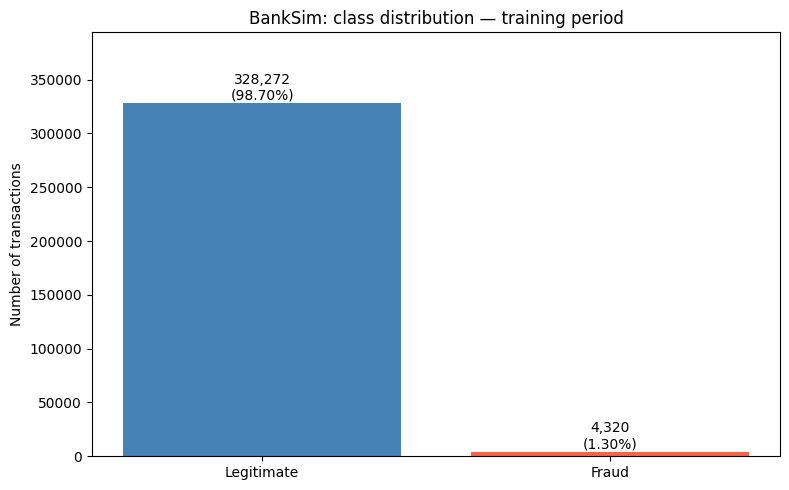

Accuracy from predicting every training transaction as legitimate: 98.70%


In [8]:
class_counts = (
    eda["fraud"].value_counts()
    .reindex([0, 1], fill_value=0)
)

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    ["Legitimate", "Fraud"],
    class_counts.values,
    color=["steelblue", "tomato"]
)

for bar, count in zip(bars, class_counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({count / len(eda):.2%})",
        ha="center",
        va="bottom"
    )

ax.set_ylim(0, class_counts.max() * 1.2)
ax.set_ylabel("Number of transactions")
ax.set_title("BankSim: class distribution — training period")

fig.tight_layout()
fig.savefig(
    ROOT / "outputs" / "01_class_distribution.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print(
    "Accuracy from predicting every training transaction as legitimate:",
    f"{(eda['fraud'] == 0).mean():.2%}"
)

,transactions,fraud_transactions,mean_amount,fraud_rate_percent
category,,,,
es_leisure,323,304,289.951,94.118
es_travel,453,342,2271.971,75.497
es_sportsandtoys,2658,1236,209.640,46.501
es_hotelservices,995,298,200.214,29.950
es_otherservices,667,132,120.035,19.790
es_home,1215,210,175.380,17.284
es_health,8297,1014,140.878,12.221
es_tech,1318,88,118.223,6.677
es_wellnessandbeauty,9054,416,65.334,4.595


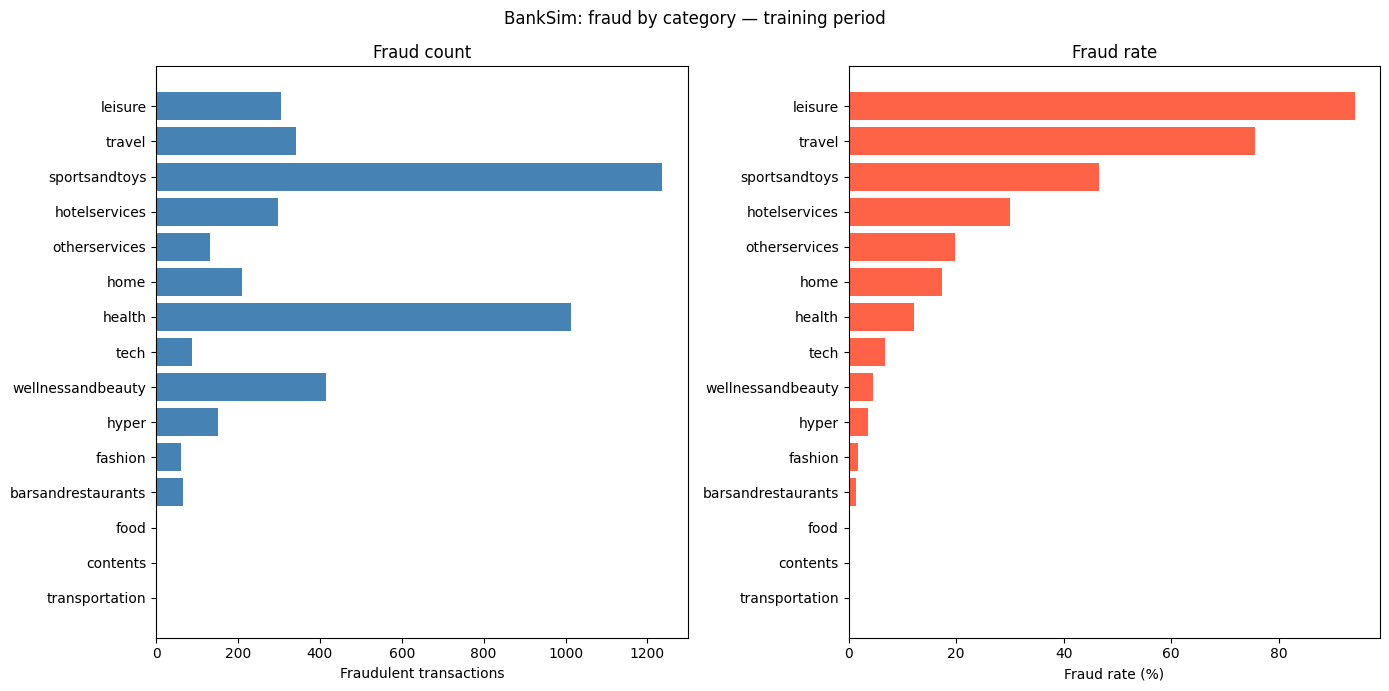

In [9]:
category_summary = (
    eda.groupby("category")
    .agg(
        transactions=("fraud", "size"),
        fraud_transactions=("fraud", "sum"),
        mean_amount=("amount", "mean")
    )
)

category_summary["fraud_rate_percent"] = (
    category_summary["fraud_transactions"]
    / category_summary["transactions"] * 100
)

category_summary = category_summary.sort_values(
    "fraud_rate_percent", ascending=False
)

display(category_summary.round(3))

category_summary.to_csv(
    ROOT / "outputs" / "training_category_summary.csv"
)

plot_data = category_summary.sort_values("fraud_rate_percent")
labels = plot_data.index.str.replace("es_", "", regex=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].barh(
    labels, plot_data["fraud_transactions"], color="steelblue"
)
axes[0].set_xlabel("Fraudulent transactions")
axes[0].set_title("Fraud count")

axes[1].barh(
    labels, plot_data["fraud_rate_percent"], color="tomato"
)
axes[1].set_xlabel("Fraud rate (%)")
axes[1].set_title("Fraud rate")

fig.suptitle("BankSim: fraud by category — training period")
fig.tight_layout()
fig.savefig(
    ROOT / "outputs" / "02_category_analysis.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

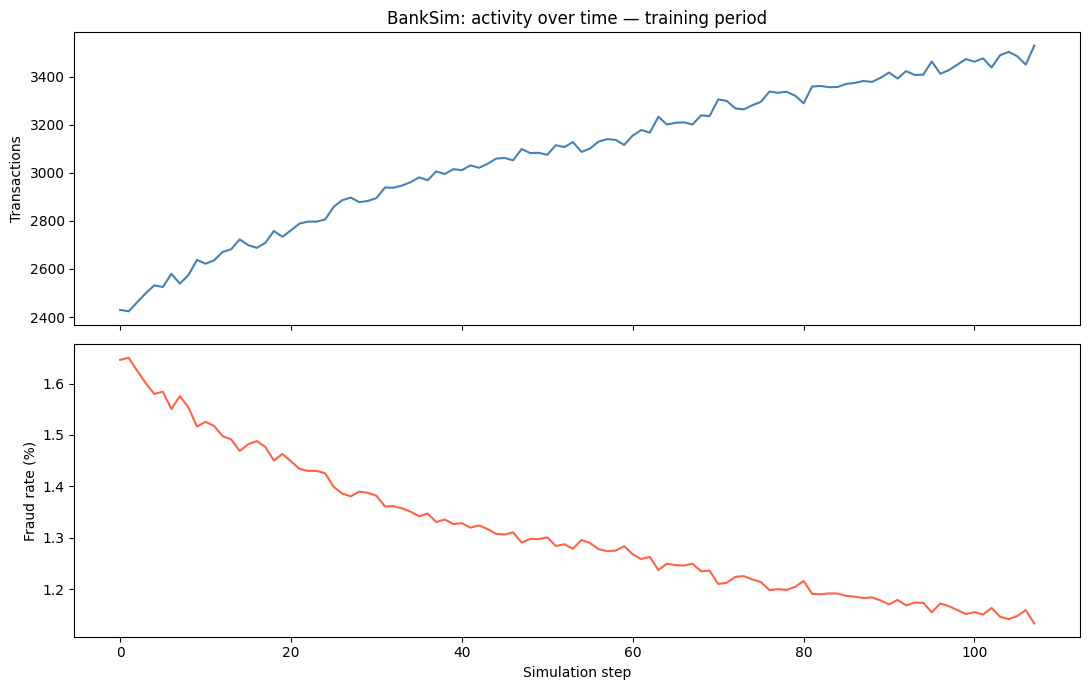

,count,mean,std,min,25%,50%,75%,max
fraud,,,,,,,,
0,328272.0,31.849399,32.248291,0.00,13.590,26.610,41.8700,2144.86
1,4320.0,542.151134,854.553235,0.04,162.305,321.575,553.4725,7665.56


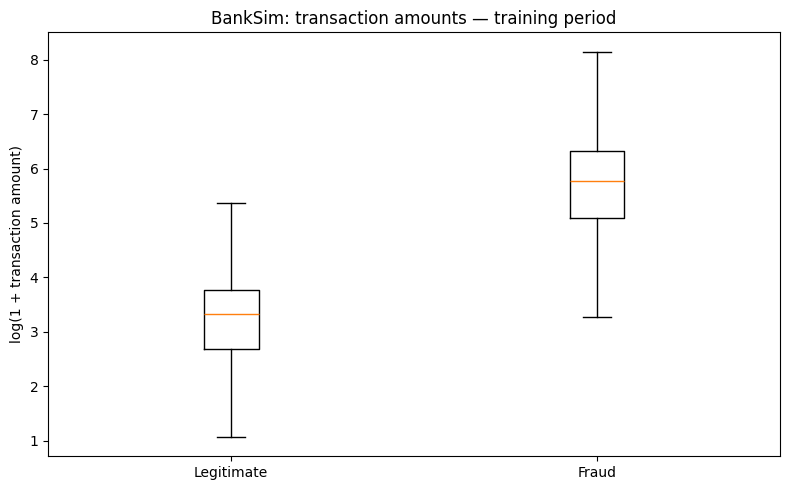

In [10]:
step_summary = (
    eda.groupby("step")
    .agg(
        transactions=("fraud", "size"),
        fraud_transactions=("fraud", "sum")
    )
)

step_summary["fraud_rate_percent"] = (
    step_summary["fraud_transactions"]
    / step_summary["transactions"] * 100
)

step_summary.to_csv(
    ROOT / "outputs" / "training_step_summary.csv"
)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(
    step_summary.index,
    step_summary["transactions"],
    color="steelblue"
)
axes[0].set_ylabel("Transactions")
axes[0].set_title("BankSim: activity over time — training period")

axes[1].plot(
    step_summary.index,
    step_summary["fraud_rate_percent"],
    color="tomato"
)
axes[1].set_ylabel("Fraud rate (%)")
axes[1].set_xlabel("Simulation step")

fig.tight_layout()
fig.savefig(
    ROOT / "outputs" / "03_time_trends.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

amount_summary = eda.groupby("fraud")["amount"].describe()
display(amount_summary)

amount_summary.to_csv(
    ROOT / "outputs" / "training_amount_summary.csv"
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.boxplot(
    [
        np.log1p(eda.loc[eda["fraud"].eq(0), "amount"]),
        np.log1p(eda.loc[eda["fraud"].eq(1), "amount"])
    ],
    showfliers=False
)

ax.set_xticks([1, 2])
ax.set_xticklabels(["Legitimate", "Fraud"])
ax.set_ylabel("log(1 + transaction amount)")
ax.set_title("BankSim: transaction amounts — training period")

fig.tight_layout()
fig.savefig(
    ROOT / "outputs" / "04_amount_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()